# Module 4 (semaine 3) – Grid search, modèles avancés et ensembles

Suite de `04_baseline.ipynb`, et application au projet de la **partie II du lab 6** :
1. **Grid search** sur la baseline (régression logistique) pour trouver sa meilleure configuration.
2. Modèles avancés : **random forest**, **gradient boosting** et un **MLP** (modèle hors cours).
3. **Ensembles** : Voting (moyenne des probabilités), Bagging et Stacking.
4. **Incertitude** : intervalles de confiance par bootstrap et comparaison appariée avec la baseline.
5. Figures et tableau comparatif (performance, temps, interprétabilité).
6. Impact de la fuite des heures de jeu (AI_AUDIT, Flaw 2).
7. Évaluation finale sur le test (désactivée tant que le modèle final n'est pas choisi).

**Règles reprises des pièges du lab 6, adaptées à notre projet**

| Piège du lab 6 | Ce qu'on fait ici |
|---|---|
| `cv=2` aléatoire | `PredefinedSplit` : le réglage se fait sur **notre validation dans le temps**, jamais sur des plis aléatoires |
| `scoring="accuracy"` | `scoring="average_precision"` (PR-AUC) : classes déséquilibrées (~15 % de succès) |
| normalisation hors pipeline | imputation, normalisation et encodage **dans** le pipeline, ajustés sur le train |
| `refit=True` | `refit=False` : avec `PredefinedSplit`, `refit=True` réentraînerait sur train + validation et on ne pourrait plus évaluer sur la validation |
| évaluer sur le test pour choisir | le test n'est utilisé **qu'une fois**, à la fin |
| `random_state` oublié | `random_state=SEED` partout |

In [1]:
import sys, time
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, BaggingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit, KFold
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)
from config import *

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

target = pd.read_parquet(PROC_DIR / "target.parquet")
static = pd.read_parquet(PROC_DIR / "features_static.parquet")
print("Jeux :", len(target), "| Variables statiques :", static.shape)

Jeux : 10000 | Variables statiques : (10000, 217)


## 0. Données et pipeline (identiques au notebook 04)

On reprend exactement `make_dataset` et le préprocesseur du notebook 04, pour que la baseline soit comparable.
Les jeux sont **triés par date de sortie** (utile pour le Stacking, section 3).

In [2]:
NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]
T_LIST = T_VALUES  # [0, 7, 30, 90]

def make_dataset(T):
    df = target[["app_id", "release_date", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df.sort_values(["release_date", "app_id"]).reset_index(drop=True)

def make_preprocess(df):
    num = [c for c in NUM_COLS if c in df.columns]
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        remainder="passthrough")

DATA = {}
for T in T_LIST:
    df = make_dataset(T)
    tr, va = df[df["split"] == "train"], df[df["split"] == "val"]
    X_cols = [c for c in df.columns if c not in ["app_id", "release_date", "split", "success"]]
    DATA[T] = dict(df=df, Xtr=tr[X_cols], ytr=tr["success"], Xva=va[X_cols], yva=va["success"])
    assert tr["release_date"].max() < va["release_date"].min()   # pas de jour partagé

print({T: DATA[T]["Xtr"].shape for T in T_LIST})
print("Proportion de succès en validation (PR-AUC du hasard) :", round(DATA[0]["yva"].mean(), 3))

{0: (7007, 216), 7: (7007, 219), 30: (7007, 219), 90: (7007, 219)}
Proportion de succès en validation (PR-AUC du hasard) : 0.157


In [3]:
def predefined_split(d):
    # train = -1 (jamais en validation), val = 0 (le seul pli de validation)
    X = pd.concat([d["Xtr"], d["Xva"]])
    y = pd.concat([d["ytr"], d["yva"]])
    fold = np.r_[np.full(len(d["Xtr"]), -1), np.zeros(len(d["Xva"]))]
    return X, y, PredefinedSplit(fold)

def evaluate(model, d, name, T, fit_time=np.nan):
    t0 = time.perf_counter()
    p = model.predict_proba(d["Xva"])[:, 1]
    pred_time = time.perf_counter() - t0
    yhat = (p >= 0.5).astype(int)
    return dict(model=name, T=T, **{"PR-AUC": average_precision_score(d["yva"], p),
                "ROC-AUC": roc_auc_score(d["yva"], p),
                "F1": f1_score(d["yva"], yhat, zero_division=0),
                "precision": precision_score(d["yva"], yhat, zero_division=0),
                "recall": recall_score(d["yva"], yhat, zero_division=0),
                "fit_s": fit_time, "predict_s": pred_time}), p

def fit_timed(model, d):
    t0 = time.perf_counter()
    model.fit(d["Xtr"], d["ytr"])
    return model, time.perf_counter() - t0

ROWS, PROBA, MODELS = [], {}, {}

def record(model, d, name, T, fit_time):
    row, p = evaluate(model, d, name, T, fit_time)
    ROWS.append(row); PROBA[(name, T)] = p; MODELS[(name, T)] = model
    return row

## 1. Baseline du notebook 04, puis grid search sur la régression logistique

La baseline du notebook 04 : `LogisticRegression(max_iter=1000, class_weight="balanced")`, avec `C = 1` et une
pénalité L2 par défaut. On cherche :
- `C` : la force de la régularisation (petit `C` = coefficients plus petits = modèle plus simple, moins de variance) ;
- `l1_ratio` : 0 = pénalité L2 (Ridge), 1 = pénalité L1 (Lasso, met des coefficients à 0 : sélection de variables) ;
- `class_weight` : `None` ou `"balanced"`.

Avec scikit-learn 1.9, le paramètre `penalty` est obsolète : on passe par `l1_ratio` avec le solveur `saga`
(seul solveur qui accepte L1 et L2).

In [4]:
LR_GRID = {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3],
           "logisticregression__l1_ratio": [0, 1],
           "logisticregression__class_weight": [None, "balanced"]}
BEST_LR = {}

for T in T_LIST:
    d = DATA[T]
    base = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    base, ft = fit_timed(base, d)
    record(base, d, "LogReg (baseline 04)", T, ft)

    pipe = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(solver="saga", max_iter=3000, random_state=SEED))
    X, y, ps = predefined_split(d)
    gs = GridSearchCV(pipe, LR_GRID, scoring="average_precision", cv=ps, refit=False, n_jobs=-1)
    gs.fit(X, y)
    BEST_LR[T] = gs.best_params_
    best, ft = fit_timed(clone(pipe).set_params(**gs.best_params_), d)   # réentraîné sur le train seul
    record(best, d, "LogReg (grid search)", T, ft)
    print(f"T={T:>2} meilleurs paramètres : {gs.best_params_} | PR-AUC val = {gs.best_score_:.3f}")

T= 0 meilleurs paramètres : {'logisticregression__C': 0.3, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.456


T= 7 meilleurs paramètres : {'logisticregression__C': 0.1, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.821


T=30 meilleurs paramètres : {'logisticregression__C': 0.1, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.862


T=90 meilleurs paramètres : {'logisticregression__C': 0.3, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.885


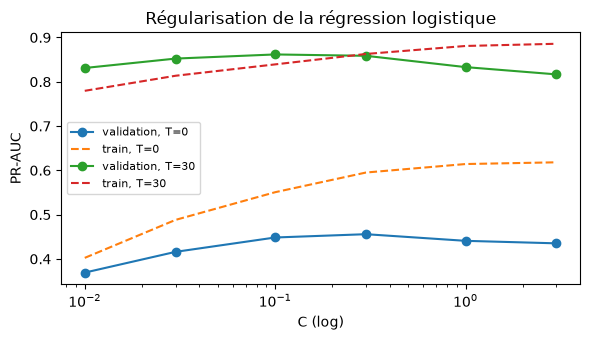

In [5]:
# Effet de C sur la PR-AUC de validation (biais / variance), à T = 0 et T = 30
fig, ax = plt.subplots(figsize=(6, 3.5))
for T in [0, 30]:
    d = DATA[T]; X, y, ps = predefined_split(d)
    pipe = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(solver="saga", max_iter=3000, random_state=SEED,
                                            l1_ratio=BEST_LR[T]["logisticregression__l1_ratio"],
                                            class_weight=BEST_LR[T]["logisticregression__class_weight"]))
    gs = GridSearchCV(pipe, {"logisticregression__C": LR_GRID["logisticregression__C"]},
                      scoring="average_precision", cv=ps, refit=False, return_train_score=True, n_jobs=-1).fit(X, y)
    r = pd.DataFrame(gs.cv_results_)
    ax.plot(r["param_logisticregression__C"], r["mean_test_score"], marker="o", label=f"validation, T={T}")
    ax.plot(r["param_logisticregression__C"], r["mean_train_score"], ls="--", label=f"train, T={T}")
ax.set(xscale="log", xlabel="C (log)", ylabel="PR-AUC", title="Régularisation de la régression logistique")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "logreg_C.png", dpi=150); plt.show()

**Lecture :** à gauche (petit `C`), le modèle est trop contraint : train et validation sont bas (**biais**).
À droite (grand `C`), le score de train continue de monter alors que la validation stagne ou baisse : le modèle
commence à apprendre le bruit du train (**variance**). Le meilleur `C` est là où la validation est au plus haut.

## 2. Modèles avancés : random forest, gradient boosting, MLP

Recherche aléatoire (`RandomizedSearchCV`, 8 combinaisons par modèle et par T, budget limité) plutôt qu'une grille complète : à budget égal,
elle explore plus de valeurs différentes de chaque paramètre (Bergstra et Bengio, 2012).

- **Random forest** : beaucoup d'arbres profonds entraînés sur des échantillons bootstrap (= du *bagging* d'arbres),
  avec un sous-ensemble aléatoire de variables à chaque coupure. La moyenne réduit la variance.
- **HistGradientBoosting** : des petits arbres ajoutés un par un, chacun corrige les erreurs des précédents (réduit le biais).
- **MLP** (*multilayer perceptron*, modèle hors cours) : un réseau de neurones à 1 ou 2 couches cachées,
  avec arrêt précoce (`early_stopping`) pour limiter le sur-apprentissage.

In [6]:
SEARCH = {
    "Random forest": (RandomForestClassifier(random_state=SEED, n_jobs=1), {
        "randomforestclassifier__n_estimators": [200, 400],
        "randomforestclassifier__max_depth": [None, 8, 16, 32],
        "randomforestclassifier__min_samples_leaf": [1, 3, 10, 30],
        "randomforestclassifier__max_features": ["sqrt", 0.2, 0.4],
        "randomforestclassifier__class_weight": [None, "balanced_subsample"]}),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=SEED), {
        "histgradientboostingclassifier__learning_rate": [0.03, 0.05, 0.1],
        "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
        "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
        "histgradientboostingclassifier__l2_regularization": [0, 0.1, 1],
        "histgradientboostingclassifier__max_iter": [200, 400],
        "histgradientboostingclassifier__class_weight": [None, "balanced"]}),
    "MLP": (MLPClassifier(early_stopping=True, max_iter=300, random_state=SEED), {
        "mlpclassifier__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64)],
        "mlpclassifier__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1],
        "mlpclassifier__learning_rate_init": [1e-3, 3e-3]}),
}
BEST_PARAMS = {}

for name, (clf, grid) in SEARCH.items():
    for T in T_LIST:
        d = DATA[T]
        pipe = make_pipeline(make_preprocess(d["df"]), clf)
        X, y, ps = predefined_split(d)
        rs = RandomizedSearchCV(pipe, grid, n_iter=8, scoring="average_precision", cv=ps,
                                refit=False, random_state=SEED, n_jobs=-1).fit(X, y)
        BEST_PARAMS[(name, T)] = rs.best_params_
        best, ft = fit_timed(clone(pipe).set_params(**rs.best_params_), d)
        row = record(best, d, name, T, ft)
        print(f"{name:<18} T={T:>2} PR-AUC val = {row['PR-AUC']:.3f}  {rs.best_params_}")

Random forest      T= 0 PR-AUC val = 0.489  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__max_depth': 32, 'randomforestclassifier__class_weight': None}


Random forest      T= 7 PR-AUC val = 0.866  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 3, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': None}


Random forest      T=30 PR-AUC val = 0.910  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': 8, 'randomforestclassifier__class_weight': None}


Random forest      T=90 PR-AUC val = 0.944  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': 8, 'randomforestclassifier__class_weight': None}


Gradient boosting  T= 0 PR-AUC val = 0.486  {'histgradientboostingclassifier__min_samples_leaf': 20, 'histgradientboostingclassifier__max_leaf_nodes': 63, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.05, 'histgradientboostingclassifier__l2_regularization': 1, 'histgradientboostingclassifier__class_weight': None}


Gradient boosting  T= 7 PR-AUC val = 0.871  {'histgradientboostingclassifier__min_samples_leaf': 20, 'histgradientboostingclassifier__max_leaf_nodes': 15, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.03, 'histgradientboostingclassifier__l2_regularization': 1, 'histgradientboostingclassifier__class_weight': None}


... (2 outputs left out)

MLP                T= 0 PR-AUC val = 0.445  {'mlpclassifier__learning_rate_init': 0.003, 'mlpclassifier__hidden_layer_sizes': (64, 32), 'mlpclassifier__alpha': 0.001}


MLP                T= 7 PR-AUC val = 0.845  {'mlpclassifier__learning_rate_init': 0.003, 'mlpclassifier__hidden_layer_sizes': (128,), 'mlpclassifier__alpha': 1}


MLP                T=30 PR-AUC val = 0.892  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (128, 64), 'mlpclassifier__alpha': 1}


MLP                T=90 PR-AUC val = 0.915  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (128, 64), 'mlpclassifier__alpha': 1}


**Remarque sur le MLP.** Sur des données tabulaires (beaucoup de variables 0/1, peu de lignes), les réseaux de
neurones font en général moins bien que les modèles à base d'arbres : c'est le résultat de
Grinsztajn, Oyallon et Varoquaux (2022), *Why do tree-based models still outperform deep learning on typical
tabular data?*, NeurIPS 2022 (Datasets and Benchmarks), et de Shwartz-Ziv et Armon (2022), *Tabular data:
Deep learning is not all you need*, Information Fusion 81. On l'utilise donc comme modèle hors cours **à
comparer**, pas comme favori. *(Références à vérifier sur Google Scholar avant de les citer dans le rapport.)*

## 3. Ensembles : Voting, Bagging, Stacking

- **Voting souple** : moyenne des probabilités de la régression logistique réglée, de la random forest et du
  gradient boosting. Utile si les modèles se trompent sur des jeux différents.
- **Bagging de la régression logistique** : 50 régressions entraînées sur des échantillons bootstrap. La régression
  logistique a peu de variance, donc on s'attend à un gain faible (contrairement aux arbres, d'où la random forest).
  On règle `n_estimators` et `max_samples` comme dans le lab 6.
- **Stacking** : un méta-modèle (régression logistique) apprend à combiner les probabilités des trois modèles.
  Il s'entraîne sur des prédictions *hors échantillon* du train (`KFold(5)` **sans mélange**, sur des jeux triés
  par date : chaque pli est une période continue, ce qui limite le mélange passé / futur).

In [7]:
def tuned(name, T):
    return MODELS[(name, T)]

for T in T_LIST:
    d = DATA[T]
    members = [("lr", clone(tuned("LogReg (grid search)", T))),
               ("rf", clone(tuned("Random forest", T))),
               ("gb", clone(tuned("Gradient boosting", T)))]

    vote, ft = fit_timed(VotingClassifier(members, voting="soft", n_jobs=-1), d)
    record(vote, d, "Voting (LR+RF+GB)", T, ft)

    X, y, ps = predefined_split(d)
    # Le préprocesseur reste AVANT le Bagging : BaggingClassifier transforme X en tableau numpy
    # et perd les noms de colonnes dont le ColumnTransformer a besoin.
    lr_best = tuned("LogReg (grid search)", T)[-1]
    bag = make_pipeline(make_preprocess(d["df"]),
                        BaggingClassifier(clone(lr_best), random_state=SEED, n_jobs=-1))
    gs = GridSearchCV(bag, {"baggingclassifier__n_estimators": [25, 50],
                            "baggingclassifier__max_samples": [0.5, 1.0]},
                      scoring="average_precision", cv=ps, refit=False).fit(X, y)
    bag, ft = fit_timed(bag.set_params(**gs.best_params_), d)
    record(bag, d, "Bagging (LogReg)", T, ft)

    stack = StackingClassifier(members, final_estimator=LogisticRegression(max_iter=1000),
                               cv=KFold(5, shuffle=False), stack_method="predict_proba", n_jobs=-1)
    stack, ft = fit_timed(stack, d)
    record(stack, d, "Stacking", T, ft)
    print(f"T={T:>2} ensembles entraînés (bagging : {gs.best_params_})")

results = pd.DataFrame(ROWS)
results.pivot(index="model", columns="T", values="PR-AUC").round(3).sort_values(30, ascending=False)

T= 0 ensembles entraînés (bagging : {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T= 7 ensembles entraînés (bagging : {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T=30 ensembles entraînés (bagging : {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 50})


T=90 ensembles entraînés (bagging : {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T,0,7,30,90
model,,,,
Gradient boosting,0.486,0.871,0.915,0.941
Stacking,0.501,0.874,0.915,0.946
Voting (LR+RF+GB),0.493,0.873,0.914,0.943
Random forest,0.489,0.866,0.910,0.944
MLP,0.445,0.845,0.892,0.915
Bagging (LogReg),0.451,0.822,0.862,0.884
LogReg (grid search),0.456,0.821,0.862,0.885
LogReg (baseline 04),0.407,0.743,0.810,0.850


## 4. Incertitude : intervalles de confiance et comparaison avec la baseline

La validation ne contient que 1 499 jeux, dont environ 235 succès : une différence de 0,01 de PR-AUC peut être
du bruit. On rééchantillonne les jeux de validation 1 000 fois (bootstrap) :
- **IC à 95 %** de la PR-AUC de chaque modèle ;
- **comparaison appariée** avec la baseline du notebook 04 : les deux modèles sont évalués **sur les mêmes jeux
  tirés**, ce qui retire la variabilité commune. Si l'intervalle de la différence contient 0, le gain n'est pas
  significatif.

Hypothèse : les jeux sont indépendants. C'est approximatif (même éditeur, même mois), donc les intervalles sont
plutôt optimistes.

In [8]:
N_BOOT = 1000
y_val = DATA[0]["yva"].to_numpy()          # les mêmes jeux de validation pour tous les T
rng = np.random.default_rng(SEED)
BOOT_IDX = [i for i in (rng.integers(0, len(y_val), len(y_val)) for _ in range(N_BOOT)) if y_val[i].any()]

def boot_scores(p):
    return np.array([average_precision_score(y_val[i], p[i]) for i in BOOT_IDX])

for T in T_LIST:
    assert (DATA[T]["yva"].to_numpy() == y_val).all()

BOOT = {key: boot_scores(p) for key, p in PROBA.items()}
results["CI_low"] = [np.percentile(BOOT[(m, T)], 2.5) for m, T in zip(results["model"], results["T"])]
results["CI_high"] = [np.percentile(BOOT[(m, T)], 97.5) for m, T in zip(results["model"], results["T"])]

diff = []
for (m, T), s in BOOT.items():
    if m == "LogReg (baseline 04)":
        continue
    delta = s - BOOT[("LogReg (baseline 04)", T)]
    diff.append(dict(model=m, T=T, gain=delta.mean(), gain_low=np.percentile(delta, 2.5),
                     gain_high=np.percentile(delta, 97.5), significant=np.percentile(delta, 2.5) > 0))
diff = pd.DataFrame(diff)
diff.pivot(index="model", columns="T", values="gain").round(3)

T,0,7,30,90
model,,,,
Bagging (LogReg),0.045,0.079,0.052,0.034
Gradient boosting,0.078,0.128,0.105,0.091
LogReg (grid search),0.049,0.078,0.052,0.036
MLP,0.037,0.101,0.081,0.065
Random forest,0.082,0.122,0.100,0.095
Stacking,0.092,0.130,0.105,0.096
Voting (LR+RF+GB),0.086,0.129,0.105,0.093


In [9]:
print("Gain de PR-AUC par rapport à la baseline 04, avec IC à 95 % (bootstrap apparié) :")
diff.assign(IC=lambda x: "[" + x["gain_low"].round(3).astype(str) + ", " + x["gain_high"].round(3).astype(str) + "]")\
    .pivot(index="model", columns="T", values="IC")

Gain de PR-AUC par rapport à la baseline 04, avec IC à 95 % (bootstrap apparié) :


T,0,7,30,90
model,,,,
Bagging (LogReg),"[0.02, 0.069]","[0.054, 0.105]","[0.033, 0.074]","[0.021, 0.048]"
Gradient boosting,"[0.032, 0.123]","[0.091, 0.168]","[0.073, 0.143]","[0.06, 0.127]"
LogReg (grid search),"[0.022, 0.075]","[0.052, 0.106]","[0.032, 0.074]","[0.021, 0.051]"
MLP,"[0.002, 0.073]","[0.074, 0.132]","[0.054, 0.11]","[0.039, 0.093]"
Random forest,"[0.028, 0.135]","[0.084, 0.163]","[0.069, 0.138]","[0.063, 0.129]"
Stacking,"[0.052, 0.134]","[0.096, 0.168]","[0.076, 0.141]","[0.068, 0.129]"
Voting (LR+RF+GB),"[0.049, 0.123]","[0.096, 0.168]","[0.076, 0.139]","[0.066, 0.126]"


## 5. Figures et tableau comparatif

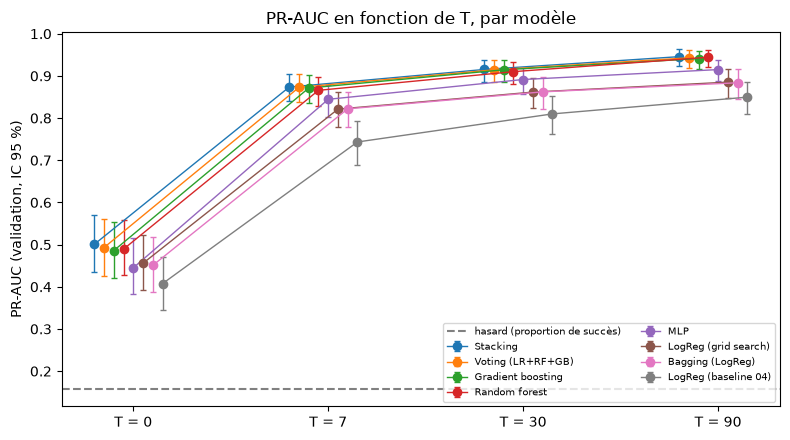

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = results.groupby("model")["PR-AUC"].mean().sort_values(ascending=False).index
for k, m in enumerate(order):
    r = results[results["model"] == m].sort_values("T")
    x = np.arange(len(T_LIST)) + (k - len(order) / 2) * 0.05
    ax.errorbar(x, r["PR-AUC"], yerr=[r["PR-AUC"] - r["CI_low"], r["CI_high"] - r["PR-AUC"]],
                marker="o", capsize=2, lw=1, label=m)
ax.axhline(y_val.mean(), color="gray", ls="--", label="hasard (proportion de succès)")
ax.set_xticks(range(len(T_LIST)), [f"T = {T}" for T in T_LIST])
ax.set(ylabel="PR-AUC (validation, IC 95 %)", title="PR-AUC en fonction de T, par modèle")
ax.legend(fontsize=7, ncol=2, loc="lower right"); plt.tight_layout()
plt.savefig(FIG_DIR / "prauc_vs_T_models.png", dpi=150); plt.show()

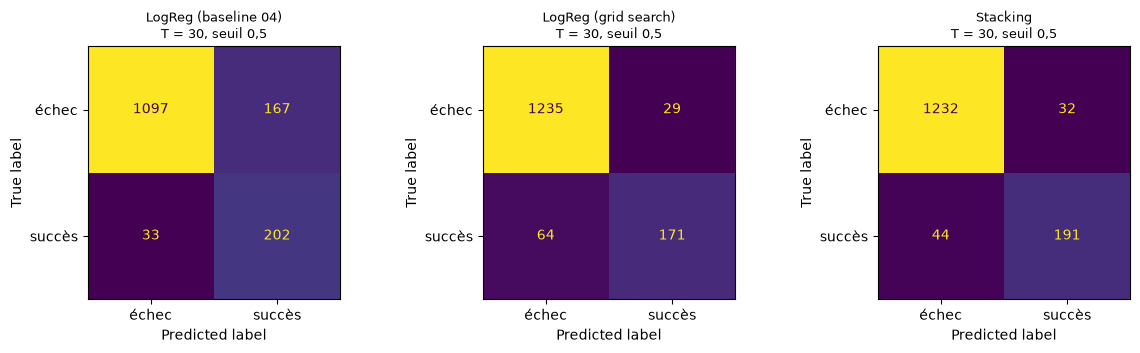

In [11]:
best_T30 = results[results["T"] == 30].sort_values("PR-AUC", ascending=False)["model"].iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, m in zip(axes, ["LogReg (baseline 04)", "LogReg (grid search)", best_T30]):
    p = PROBA[(m, 30)]
    ConfusionMatrixDisplay.from_predictions(y_val, (p >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["échec", "succès"])
    ax.set_title(f"{m}\nT = 30, seuil 0,5", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_T30.png", dpi=150); plt.show()

In [12]:
INTERPRETABILITY = {
    "LogReg (baseline 04)": "élevée (coefficients)", "LogReg (grid search)": "élevée (coefficients)",
    "Bagging (LogReg)": "moyenne (moyenne de 25-50 modèles)", "Random forest": "faible (importances seulement)",
    "Gradient boosting": "faible (importances seulement)", "MLP": "très faible (boîte noire)",
    "Voting (LR+RF+GB)": "faible", "Stacking": "faible"}
table = results[results["T"] == 30][["model", "PR-AUC", "CI_low", "CI_high", "ROC-AUC", "F1", "fit_s", "predict_s"]].copy()
table["interprétabilité"] = table["model"].map(INTERPRETABILITY)
table = table.sort_values("PR-AUC", ascending=False).round(3)
table

,model,PR-AUC,CI_low,CI_high,ROC-AUC,F1,fit_s,predict_s,interprétabilité
28,Stacking,0.915,0.885,0.938,0.973,0.834,17.871,0.111,faible
14,Gradient boosting,0.915,0.886,0.938,0.974,0.835,1.680,0.033,faible (importances seulement)
26,Voting (LR+RF+GB),0.914,0.885,0.938,0.972,0.835,7.346,0.123,faible
10,Random forest,0.910,0.880,0.934,0.973,0.838,5.770,0.066,faible (importances seulement)
18,MLP,0.892,0.858,0.919,0.967,0.806,1.538,0.026,très faible (boîte noire)
27,Bagging (LogReg),0.862,0.823,0.897,0.957,0.780,59.284,0.242,moyenne (moyenne de 25-50 modèles)
5,LogReg (grid search),0.862,0.823,0.896,0.956,0.786,0.969,0.018,élevée (coefficients)
4,LogReg (baseline 04),0.810,0.763,0.852,0.943,0.669,0.156,0.017,élevée (coefficients)


In [13]:
results.round(4).to_csv(ROOT / "report" / "results_models.csv", index=False)
diff.round(4).to_csv(ROOT / "report" / "results_models_vs_baseline.csv", index=False)
print("écrit : report/results_models.csv, report/results_models_vs_baseline.csv, report/figures/*.png")

écrit : report/results_models.csv, report/results_models_vs_baseline.csv, report/figures/*.png


## 6. Impact de la fuite des heures de jeu (AI_AUDIT, Flaw 2)

Le module 3 a retiré `hours_mean` et `hours_median` des signaux précoces : les heures sont lues **au moment de la
collecte**, pas au moment de l'avis (13,6 % des avis du premier mois ont plus d'heures que le temps écoulé depuis
la sortie). Il manquait l'impact sur le modèle. On recalcule ces deux variables à T = 30 depuis
`data/raw/recommendations.csv`, pour les mêmes jeux et avec la même fenêtre `0 <= days < 30`, et on compare la
baseline du notebook 04 avec et sans elles.

In [14]:
raw = RAW_DIR / "recommendations.csv"
if raw.exists():
    rel = target.set_index("app_id")["release_date"]
    rev = pd.read_csv(raw, usecols=["app_id", "date", "hours"], engine="pyarrow")
    rev = rev[rev["app_id"].isin(rel.index)]
    rev["days"] = (pd.to_datetime(rev["date"]) - rev["app_id"].map(rel)).dt.days
    hours = (rev[(rev["days"] >= 0) & (rev["days"] < 30)]
             .groupby("app_id")["hours"].agg(hours_mean="mean", hours_median="median"))

    d = DATA[30]
    with_h = dict(d)  # mêmes jeux et même cible, on ajoute seulement les deux colonnes d'heures
    with_h["Xtr"] = d["Xtr"].assign(**hours.reindex(d["df"].loc[d["Xtr"].index, "app_id"]).set_index(d["Xtr"].index))
    with_h["Xva"] = d["Xva"].assign(**hours.reindex(d["df"].loc[d["Xva"].index, "app_id"]).set_index(d["Xva"].index))

    NUM_H = NUM_COLS + ["hours_mean", "hours_median"]
    pre_h = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_H),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS), remainder="passthrough")
    m_h = make_pipeline(pre_h, LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    m_h.fit(with_h["Xtr"], with_h["ytr"])
    p_h = m_h.predict_proba(with_h["Xva"])[:, 1]
    ap_without = average_precision_score(y_val, PROBA[("LogReg (baseline 04)", 30)])
    ap_with = average_precision_score(y_val, p_h)
    delta = boot_scores(p_h) - BOOT[("LogReg (baseline 04)", 30)]
    print(f"PR-AUC val à T=30 : sans les heures {ap_without:.3f} | avec les heures (fuite) {ap_with:.3f}")
    print(f"différence {ap_with - ap_without:+.3f}, IC 95 % [{np.percentile(delta, 2.5):+.3f}, {np.percentile(delta, 97.5):+.3f}]")
else:
    print("data/raw/recommendations.csv absent : section ignorée")

PR-AUC val à T=30 : sans les heures 0.810 | avec les heures (fuite) 0.809
différence -0.001, IC 95 % [-0.005, +0.003]


## 7. Évaluation finale sur le test (une seule fois)

Le test n'a servi à rien jusqu'ici. Quand le groupe aura choisi le modèle final **sur la validation**, on passe
`RUN_TEST = True` et on relance **une seule fois** : le modèle est réentraîné sur train + validation, puis évalué
sur le test avec un IC à 95 %. Le seuil de décision (pour le F1) est choisi sur la validation, pas sur le test.

In [15]:
RUN_TEST = False
FINAL_MODEL, FINAL_T = best_T30, 30   # à confirmer avec le groupe

if RUN_TEST:
    df = DATA[FINAL_T]["df"]
    X_cols = DATA[FINAL_T]["Xtr"].columns
    trva, te = df[df["split"].isin(["train", "val"])], df[df["split"] == "test"]
    # seuil qui maximise le F1 sur la validation
    p_val = PROBA[(FINAL_MODEL, FINAL_T)]
    thr = max(np.linspace(0.05, 0.95, 91), key=lambda t: f1_score(y_val, (p_val >= t).astype(int)))
    model = clone(MODELS[(FINAL_MODEL, FINAL_T)]).fit(trva[X_cols], trva["success"])
    p = model.predict_proba(te[X_cols])[:, 1]
    y_te = te["success"].to_numpy()
    idx = [i for i in (np.random.default_rng(SEED).integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)) if y_te[i].any()]
    s = [average_precision_score(y_te[i], p[i]) for i in idx]
    print(f"TEST {FINAL_MODEL}, T={FINAL_T} : PR-AUC = {average_precision_score(y_te, p):.3f} "
          f"[{np.percentile(s, 2.5):.3f}, {np.percentile(s, 97.5):.3f}], ROC-AUC = {roc_auc_score(y_te, p):.3f}, "
          f"F1 (seuil {thr:.2f} choisi sur la validation) = {f1_score(y_te, (p >= thr).astype(int)):.3f}")
else:
    print("Test non utilisé (RUN_TEST = False).")

Test non utilisé (RUN_TEST = False).
